# EN3160 — Assignment 2: Fitting and Alignment



In [8]:

from pathlib import Path
import math
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import gaussian_laplace, maximum_filter
from scipy.optimize import minimize

ROOT = Path.cwd()
IMAGE_DIR = ROOT / "images"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=4, suppress=True)
print("OpenCV:", cv.__version__)
print("Working directory:", ROOT)

OpenCV: 5.0.0
Working directory: /content


## Question 1 — Blob detection using the Laplacian of Gaussian

Detect scale-space maxima of the scale-normalized Laplacian of Gaussian. A detected blob with scale $\sigma$ is displayed as a circle of radius $r \approx \sqrt{2}\sigma$. No Hough-circle detector is used.

In [9]:
SUNFLOWER_PATH = IMAGE_DIR / "/content/the_berry_farms_sunflower_field.jpeg"
SIGMAS = np.arange(1.5, 22.5, 0.75)       # Scales, in reduced-image pixels
PEAK_THRESHOLD_FRACTION = 0.12            # Fraction of the strongest LoG response
MAX_CANDIDATES = 4000
MAX_CIRCLES_TO_DRAW = 35
REDUCTION_FACTOR = 4                       # cv.IMREAD_REDUCED_COLOR_4

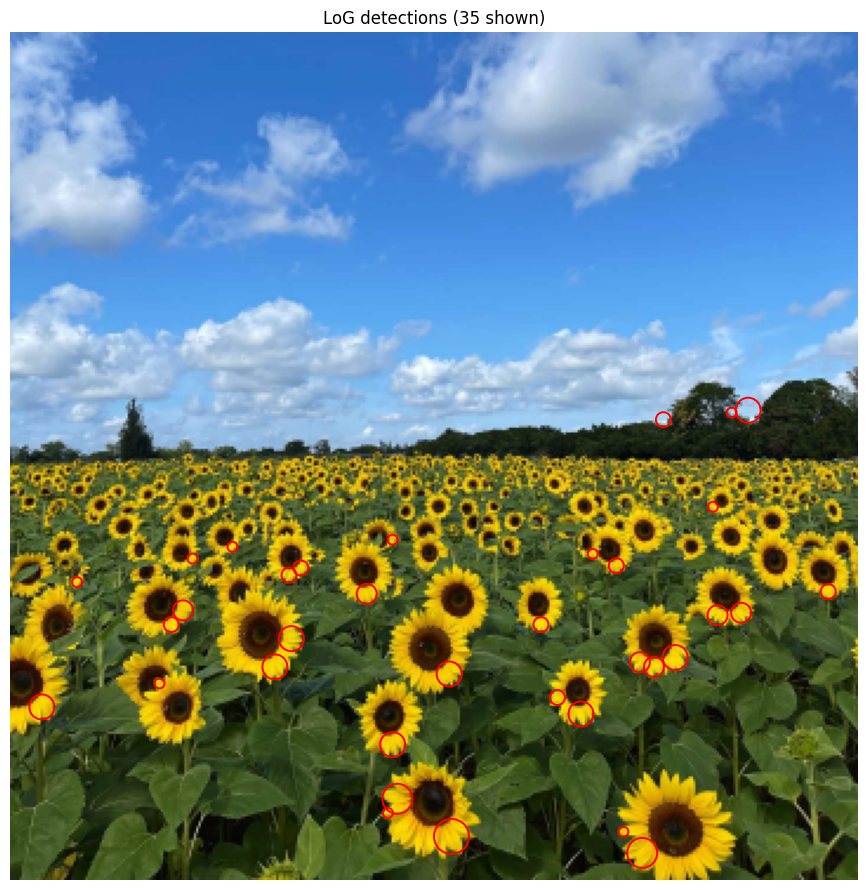

Sigma range: 1.50 to 21.75 reduced-image pixels
Largest detected circles (coordinates and radii in reduced-image pixels):
  #       x       y    sigma   radius   radius (original px)   score
  1      91     145    21.75    30.76               123.04   0.1237
  2      28      64    16.50    23.33                93.34   0.1461
  3     221      24    12.75    18.03                72.12   0.1316
  4     269     150    12.00    16.97                67.88   0.1821
  5     203     153    12.00    16.97                67.88   0.1355
  6     287      19    10.50    14.85                59.40   0.0644
  7     121      48     9.00    12.73                50.91   0.1432
  8     108     123     8.25    11.67                46.67   0.1133
  9     182      37     8.25    11.67                46.67   0.0595
 10     170     275     7.50    10.61                42.43   0.1598


In [10]:
def detect_log_blobs(gray, sigmas, threshold_fraction=0.12, nms_overlap=0.6):
    """Bright-blob LoG detector with local maxima in (sigma, y, x)."""
    normalized = gray.astype(np.float32) / 255.0
    responses = np.stack([
        -(float(sigma) ** 2) * gaussian_laplace(normalized, sigma=float(sigma))
        for sigma in sigmas
    ], axis=0)

    local_max = maximum_filter(responses, size=(3, 9, 9), mode="nearest")
    cutoff = max(float(responses.max()) * threshold_fraction, 1e-9)
    peak_locations = np.argwhere((responses == local_max) & (responses >= cutoff))
    scores = responses[tuple(peak_locations.T)] if len(peak_locations) else np.empty(0)
    order = np.argsort(scores)[::-1][:MAX_CANDIDATES]

    detected = []
    height, width = gray.shape
    for idx in order:
        scale_idx, y, x = map(int, peak_locations[idx])
        sigma = float(sigmas[scale_idx])
        radius = np.sqrt(2.0) * sigma
        if x < radius or x >= width - radius or y < radius or y >= height - radius:
            continue
        if any(np.hypot(x - other["x"], y - other["y"]) < nms_overlap * max(radius, other["radius"])
               for other in detected):
            continue
        detected.append({"x": x, "y": y, "sigma": sigma,
                         "radius": float(radius), "score": float(scores[idx])})
    return detected

if not SUNFLOWER_PATH.is_file():
    print("Missing sunflower image:", SUNFLOWER_PATH)
else:
    sunflower = cv.imread(str(SUNFLOWER_PATH), cv.IMREAD_REDUCED_COLOR_4)
    if sunflower is None:
        raise ValueError(f"Cannot read {SUNFLOWER_PATH}")
    gray = cv.cvtColor(sunflower, cv.COLOR_BGR2GRAY)
    detections = detect_log_blobs(gray, SIGMAS, PEAK_THRESHOLD_FRACTION)
    largest = sorted(detections, key=lambda item: item["radius"], reverse=True)

    fig, ax = plt.subplots(figsize=(13, 9))
    ax.imshow(cv.cvtColor(sunflower, cv.COLOR_BGR2RGB))
    for blob in detections[:MAX_CIRCLES_TO_DRAW]:
        ax.add_patch(Circle((blob["x"], blob["y"]), blob["radius"],
                            edgecolor="red", fill=False, linewidth=1.4))
    ax.set_title(f"LoG detections ({min(len(detections), MAX_CIRCLES_TO_DRAW)} shown)")
    ax.set_axis_off()
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "q1_sunflower_log_circles.png", dpi=180, bbox_inches="tight")
    plt.show()

    print(f"Sigma range: {SIGMAS[0]:.2f} to {SIGMAS[-1]:.2f} reduced-image pixels")
    print("Largest detected circles (coordinates and radii in reduced-image pixels):")
    print("  #       x       y    sigma   radius   radius (original px)   score")
    for i, blob in enumerate(largest[:10], 1):
        print(f'{i:3d} {blob["x"]:7d} {blob["y"]:7d} {blob["sigma"]:8.2f} '
              f'{blob["radius"]:8.2f} {REDUCTION_FACTOR * blob["radius"]:20.2f} '
              f'{blob["score"]:8.4f}')